## Step 0 — Imports and device selection
**What changed:** This cell establishes the tools used throughout the experiments and selects CUDA, Apple MPS, or CPU automatically. No model or training behavior is changed here; it prepares the environment for fair comparisons.

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import transforms
from torchvision.datasets import EMNIST
from torch.utils.data import DataLoader

import numpy as np
from tqdm import trange
from matplotlib import pyplot as plt

# Get cpu, gpu or mps device for training.
device = ("cuda" if torch.cuda.is_available()
          else "mps" if torch.backends.mps.is_available()
          else "cpu")
print(f"Using {device} device")

Using cuda device


## Step 1 — Add training-history plots
**What changed:** Added a reusable visualization function to compare training vs. test loss and accuracy across epochs. These plots help identify whether later experiments improve accuracy or show overfitting.

In [ ]:

def plot_results(train_losses, train_accs, test_losses, test_accs):
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    xs = np.arange(1, len(train_losses) + 1, 1)
    axes[0].plot(xs, train_losses, label='Train')
    axes[0].plot(xs, test_losses, label='Test')
    axes[0].set_title('Loss')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].set_xticks(xs)
    axes[1].plot(xs, train_accs, label='Train')
    axes[1].plot(xs, test_accs, label='Test')
    axes[1].set_title('Accuracy')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Accuracy')
    axes[1].set_xticks(xs)
    plt.tight_layout()
    plt.legend()
    plt.show()

## Step 2 — Define the training and evaluation workflow
**What changed:** Added reusable training, testing, and model-training functions. They track loss and accuracy for both datasets so the following model/optimizer experiments can be compared consistently. The test set is evaluated each epoch, so use it for comparison rather than repeated tuning if you want an unbiased final estimate.

In [ ]:

def train_step(model, criterion, optimizer, dataloader, device=device):
    running_loss, correct = 0, 0
    # Move the model to training mode
    model.train()
    # Iterate over the dataloader
    for x, y in dataloader:
        # Move the datapoints to same device as the model
        x, y = x.to(device), y.to(device)
        # Clear the gradients
        optimizer.zero_grad()
        # Predict the output and perform the forward pass
        pred = model(x)
        # Compute prediction error
        loss = criterion(pred, y)
        # Backpropagation
        loss.backward()
        # Update the model weights
        optimizer.step()
        # Update the running loss
        running_loss += loss.item()
        # Update the correctly predicted counter
        correct += (pred.argmax(1) == y).type(torch.float).sum().item()
    # Calculate and return the average loss and accuracy
    return running_loss / len(dataloader), 100 * correct / len(dataloader.dataset)


def test_step(model, criterion, dataloader, device=device):
    running_loss, correct = 0, 0
    # Move the model to training mode
    model.eval()
    # Disable gradient calculation
    with torch.no_grad():
      # Iterate over the dataloader
      for x, y in dataloader:
          # Move the datapoints to same device as the model
          x, y = x.to(device), y.to(device)
          # Predict the output and perform the forward pass
          pred = model(x)
          # Update the running loss
          running_loss += criterion(pred, y).item()
          # Update the correctly predicted counter
          correct += (pred.argmax(1) == y).type(torch.float).sum().item()
    # Calculate and return the average accuracy
    return running_loss / len(dataloader), 100 * correct / len(dataloader.dataset)


def train_model(model, n_epochs, optimizer, train_loader, test_loader, device=device):
    criterion = nn.CrossEntropyLoss()
    train_losses, train_accs = [], []
    test_losses, test_accs = [], []
    for epoch in (pbar := trange(n_epochs)):
        # Train the model
        train_loss, train_acc = train_step(model, criterion, optimizer, train_loader, device)
        # Evaluate the model
        test_loss, test_acc = test_step(model, criterion, test_loader, device)
        # Display the results
        pbar.set_description(f'Train Loss = {train_loss:.3f} | Train Acc = {train_acc:.2f}% | Test Loss = {test_loss:.3f} | Test Acc = {test_acc:.2f}% ')
        # Store the results
        train_losses.append(train_loss), train_accs.append(train_acc), test_losses.append(test_loss), test_accs.append(test_acc)
    # Plot the results
    plot_results(train_losses, train_accs, test_losses, test_accs)
    return {'train_loss': train_losses, 'train_acc': train_accs, 'test_loss': test_losses, 'test_acc': test_accs}

## Step 3 — Load and normalize EMNIST Balanced
**What changed:** The experiment uses the EMNIST Balanced character dataset and converts images to tensors, then normalizes pixel values. Normalization helps keep input scales consistent during optimization; the same transform is applied to training and test data.

In [4]:
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])

train_dataset = EMNIST(root='./data', split='balanced', train=True, download=True, transform=transform)
test_dataset = EMNIST(root='./data', split='balanced', train=False, download=True, transform=transform)

print(f'Train dataset size: {len(train_dataset)}')
print(f'Test dataset size: {len(test_dataset)}')

classes = train_dataset.classes
print(f'Classes:\n{classes}')

Train dataset size: 112800
Test dataset size: 18800
Classes:
['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'a', 'b', 'd', 'e', 'f', 'g', 'h', 'n', 'q', 'r', 't']


## Step 4 — Create data loaders
**What changed:** Added mini-batch loading with batches of 64. Training batches are shuffled to reduce dependence on sample order, while test batches remain ordered. These settings define how data is fed into each model.

In [5]:
train_loader = DataLoader(dataset=train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=64, shuffle=False)

# Iterate over the data
for x, y in test_loader:
    print(f"Shape of X [N, C, H, W]: {x.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")
    break

Shape of X [N, C, H, W]: torch.Size([64, 1, 28, 28])
Shape of y: torch.Size([64]) torch.int64


## Step 5 — Establish the SimpleNN baseline
**What changed:** Introduced a fully connected neural network with hidden layers of 128, 128, and 64 units. This is the baseline architecture against which the optimizer and larger-network experiments are compared.

In [6]:
class SimpleNN(nn.Module):
    def __init__(self, input_size, num_classes):
        super(SimpleNN, self).__init__()
        self.network = nn.Sequential(nn.Flatten(), nn.Linear(input_size, 128),
                                     nn.ReLU(), nn.Linear(128, 128),
                                     nn.ReLU(), nn.Linear(128, 64),
                                     nn.ReLU(), nn.Linear(64, num_classes))

    def forward(self, x):
        return self.network(x)

## Step 6 — Baseline experiment: SGD
**What changed:** Trained the baseline `SimpleNN` using SGD with a learning rate of 0.001 for 30 epochs. This provides a reference result for comparing a different optimizer. No code changes were made to the experiment.

Train Loss = 1.167 | Train Acc = 66.44% | Test Loss = 1.178 | Test Acc = 65.82% : 100%|██████████| 30/30 [11:52<00:00, 23.76s/it]


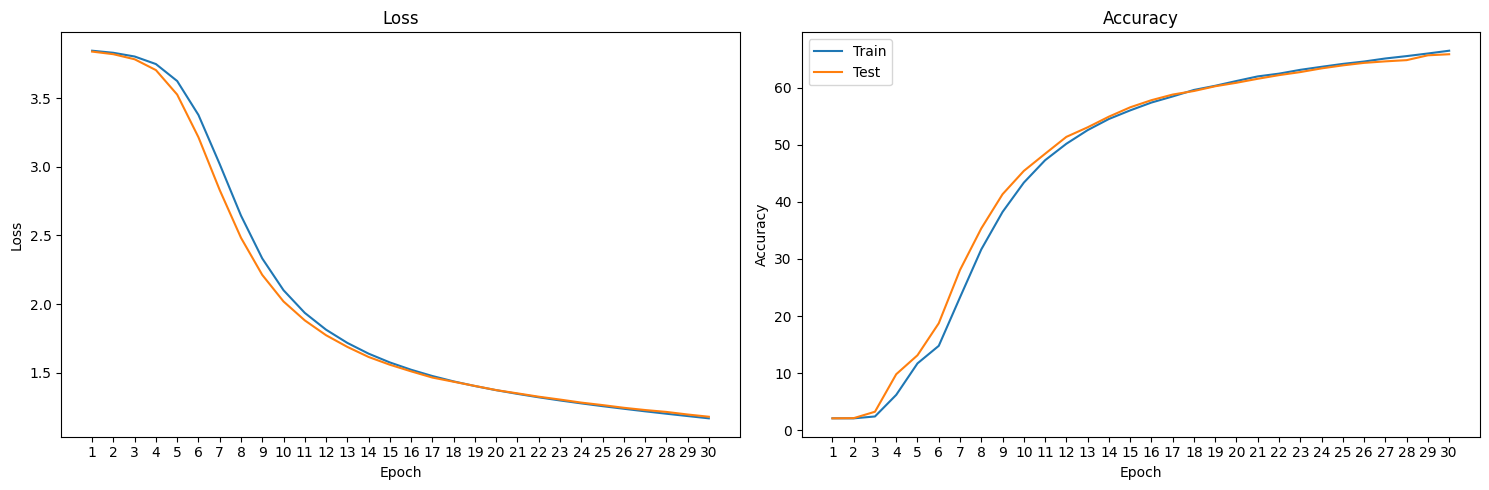

In [7]:
model = SimpleNN(input_size=28*28, num_classes=len(classes)).to(device)

optimizer = optim.SGD(model.parameters(), lr=0.001)

results = train_model(model, 30, optimizer, train_loader, test_loader)

## Step 7 — Compare Adam on the same baseline
**What changed:** Kept the `SimpleNN` architecture and learning rate the same, but switched the optimizer from SGD to Adam and trained for 20 epochs. This isolates the optimizer change more clearly than changing several settings at once.

Train Loss = 0.369 | Train Acc = 86.38% | Test Loss = 0.569 | Test Acc = 82.60% : 100%|██████████| 20/20 [08:21<00:00, 25.06s/it]


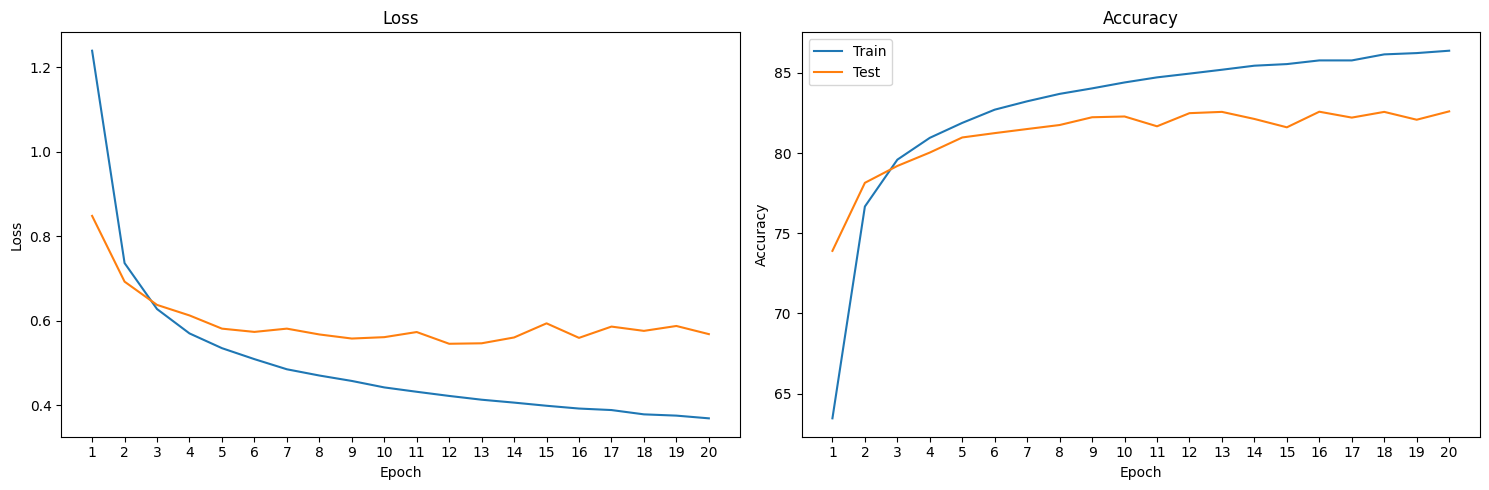

In [8]:
model = SimpleNN(input_size=28*28, num_classes=len(classes)).to(device)

optimizer = optim.Adam(model.parameters(), lr=0.001)

results = train_model(model, 20, optimizer, train_loader, test_loader)

## Step 8 — Increase model capacity with BiggerNN
**What changed:** Defined a deeper and wider fully connected network, with hidden layers ranging from 512 down to 64 units. More capacity may help learn character patterns, but it can also increase training time and overfitting risk.

In [9]:
class BiggerNN(nn.Module):
    def __init__(self, input_size, num_classes):
        super(BiggerNN, self).__init__()
        self.network = nn.Sequential(nn.Flatten(), nn.Linear(input_size, 512),
                                     nn.ReLU(), nn.Linear(512, 512),
                                     nn.ReLU(), nn.Linear(512, 512),
                                     nn.ReLU(), nn.Linear(512, 256),
                                     nn.ReLU(), nn.Linear(256, 256),
                                     nn.ReLU(), nn.Linear(256, 256),
                                     nn.ReLU(), nn.Linear(256, 128),
                                     nn.ReLU(), nn.Linear(128, 128),
                                     nn.ReLU(), nn.Linear(128, 128),
                                     nn.ReLU(), nn.Linear(128, 64),
                                     nn.ReLU(), nn.Linear(64, 64),
                                     nn.ReLU(), nn.Linear(64, 64),
                                     nn.ReLU(), nn.Linear(64, num_classes))

    def forward(self, x):
        return self.network(x)

## Step 9 — Train the larger network with Adam
**What changed:** Applied Adam (learning rate 0.001) to `BiggerNN` for 20 epochs. Compare its training and test accuracy with the simpler model to see whether the extra capacity improves generalization.

Train Loss = 0.411 | Train Acc = 86.54% | Test Loss = 0.556 | Test Acc = 83.70% : 100%|██████████| 20/20 [11:12<00:00, 33.61s/it]


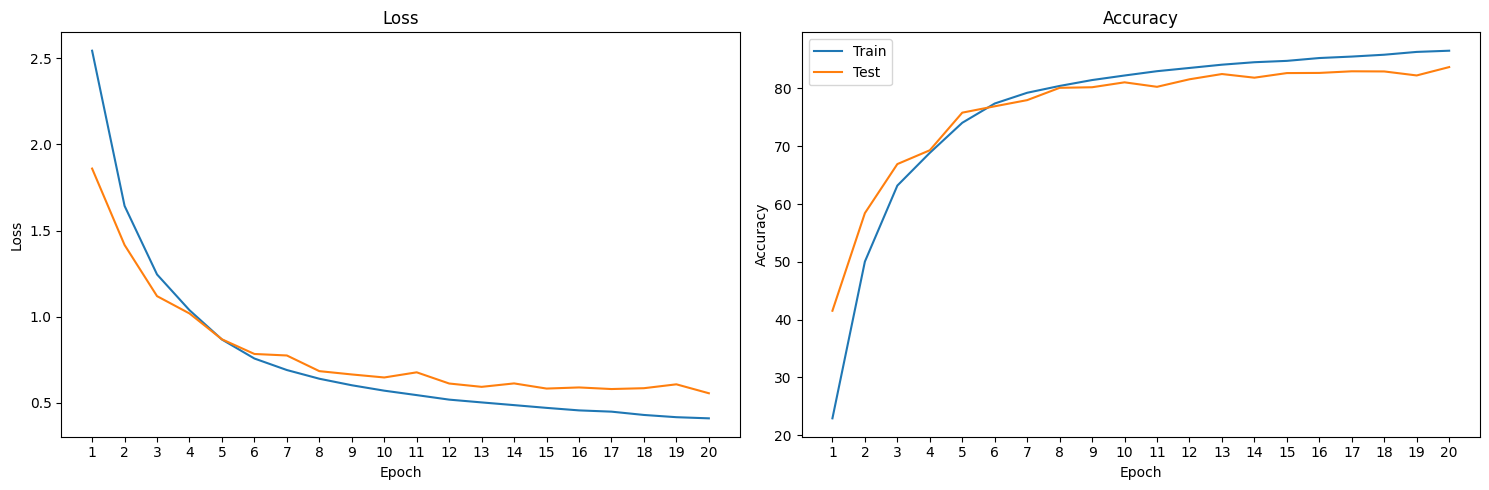

In [10]:
model = BiggerNN(input_size=28*28, num_classes=len(classes)).to(device)

optimizer = optim.Adam(model.parameters(), lr=0.001)

results = train_model(model, 20, optimizer, train_loader, test_loader)

## Step 10 — Add batch normalization
**What changed:** Defined `BiggerBN`, adding batch-normalization layers after hidden linear layers. Batch normalization can make optimization more stable and may improve convergence, though its benefit should be judged by test accuracy and loss.

In [11]:
class BiggerBN(nn.Module):
    def __init__(self, input_size, num_classes):
        super(BiggerBN, self).__init__()
        self.network = nn.Sequential(nn.Flatten(), nn.Linear(28*28, 512), nn.BatchNorm1d(512),
                                     nn.ReLU(), nn.Linear(512, 512), nn.BatchNorm1d(512),
                                     nn.ReLU(), nn.Linear(512, 512), nn.BatchNorm1d(512),
                                     nn.ReLU(), nn.Linear(512, 256), nn.BatchNorm1d(256),
                                     nn.ReLU(), nn.Linear(256, 256), nn.BatchNorm1d(256),
                                     nn.ReLU(), nn.Linear(256, 256), nn.BatchNorm1d(256),
                                     nn.ReLU(), nn.Linear(256, 128), nn.BatchNorm1d(128),
                                     nn.ReLU(), nn.Linear(128, 128), nn.BatchNorm1d(128),
                                     nn.ReLU(), nn.Linear(128, 128), nn.BatchNorm1d(128),
                                     nn.ReLU(), nn.Linear(128, 128), nn.BatchNorm1d(128),
                                     nn.ReLU(), nn.Linear(128, 64), nn.BatchNorm1d(64),
                                     nn.ReLU(), nn.Linear(64, 64), nn.BatchNorm1d(64),
                                     nn.ReLU(), nn.Linear(64, 64), nn.BatchNorm1d(64),
                                     nn.ReLU(), nn.Linear(64, num_classes))

    def forward(self, x):
        return self.network(x)

## Step 11 — Train the batch-normalized network
**What changed:** Trained `BiggerBN` with Adam at a learning rate of 0.001 for 20 epochs. This tests the effect of batch normalization relative to the larger network without batch normalization.

Train Loss = 0.273 | Train Acc = 89.87% | Test Loss = 0.421 | Test Acc = 86.35% : 100%|██████████| 20/20 [19:07<00:00, 57.38s/it]


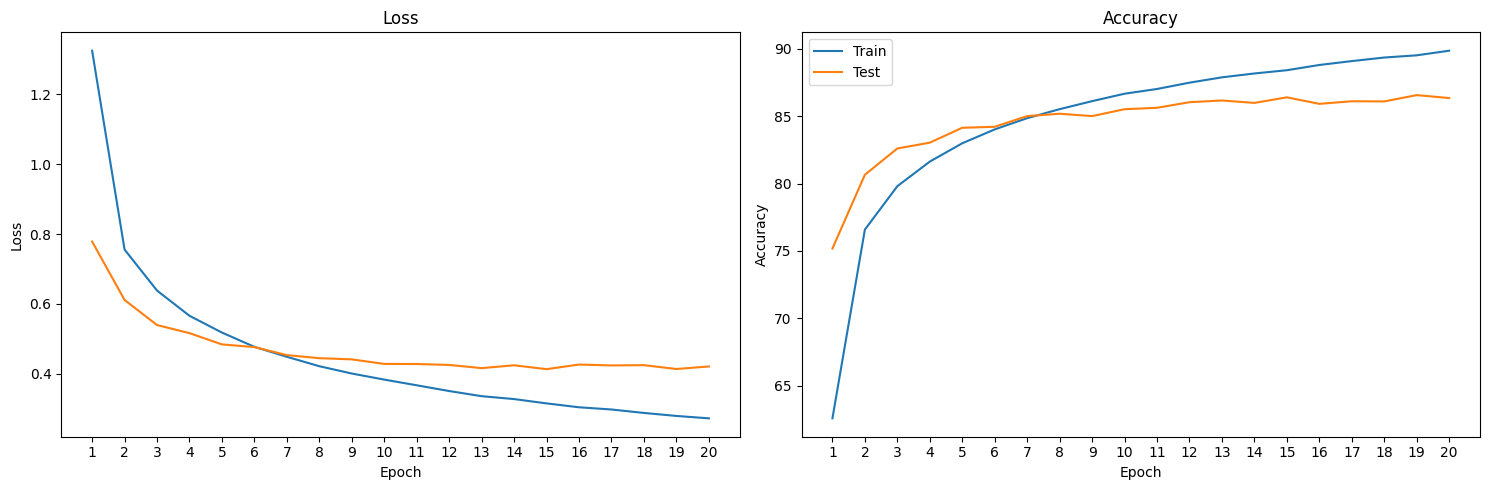

In [12]:
model = BiggerBN(input_size=28*28, num_classes=len(classes)).to(device)

optimizer = optim.Adam(model.parameters(), lr=0.001)

results = train_model(model, 20, optimizer, train_loader, test_loader)

## Step 12 — Add dropout regularization
**What changed:** Defined `BiggerDO`, combining batch normalization with dropout in the hidden layers. Dropout randomly disables some activations during training and may reduce overfitting; the dropout rates decrease in later, narrower layers.

In [13]:
class BiggerDO(nn.Module):
    def __init__(self, input_size, num_classes):
        super(BiggerDO, self).__init__()
        self.network = nn.Sequential(
            nn.Flatten(), nn.Linear(28*28, 512), nn.BatchNorm1d(512),
            nn.ReLU(), nn.Dropout(0.20), nn.Linear(512, 512), nn.BatchNorm1d(512),
            nn.ReLU(), nn.Dropout(0.20), nn.Linear(512, 512), nn.BatchNorm1d(512),
            nn.ReLU(), nn.Dropout(0.20), nn.Linear(512, 256), nn.BatchNorm1d(256),
            nn.ReLU(), nn.Dropout(0.15), nn.Linear(256, 256), nn.BatchNorm1d(256),
            nn.ReLU(), nn.Dropout(0.15), nn.Linear(256, 256), nn.BatchNorm1d(256),
            nn.ReLU(), nn.Dropout(0.15), nn.Linear(256, 128), nn.BatchNorm1d(128),
            nn.ReLU(), nn.Dropout(0.10), nn.Linear(128, 128), nn.BatchNorm1d(128),
            nn.ReLU(), nn.Dropout(0.10), nn.Linear(128, 128), nn.BatchNorm1d(128),
            nn.ReLU(), nn.Dropout(0.10), nn.Linear(128, 64), nn.BatchNorm1d(64),
            nn.ReLU(), nn.Dropout(0.05), nn.Linear(64, 64), nn.BatchNorm1d(64),
            nn.ReLU(), nn.Dropout(0.05), nn.Linear(64, 64), nn.BatchNorm1d(64),
            nn.ReLU(), nn.Dropout(0.05), nn.Linear(64, num_classes))

    def forward(self, x):
        return self.network(x)

## Step 13 — Train the dropout model
**What changed:** Trained `BiggerDO` with Adam at a learning rate of 0.001 for 20 epochs. Compare training and test curves with `BiggerBN`: lower training accuracy alongside better test accuracy can indicate that dropout is helping generalization.

Train Loss = 0.475 | Train Acc = 84.63% | Test Loss = 0.408 | Test Acc = 86.55% : 100%|██████████| 20/20 [12:01<00:00, 36.08s/it]


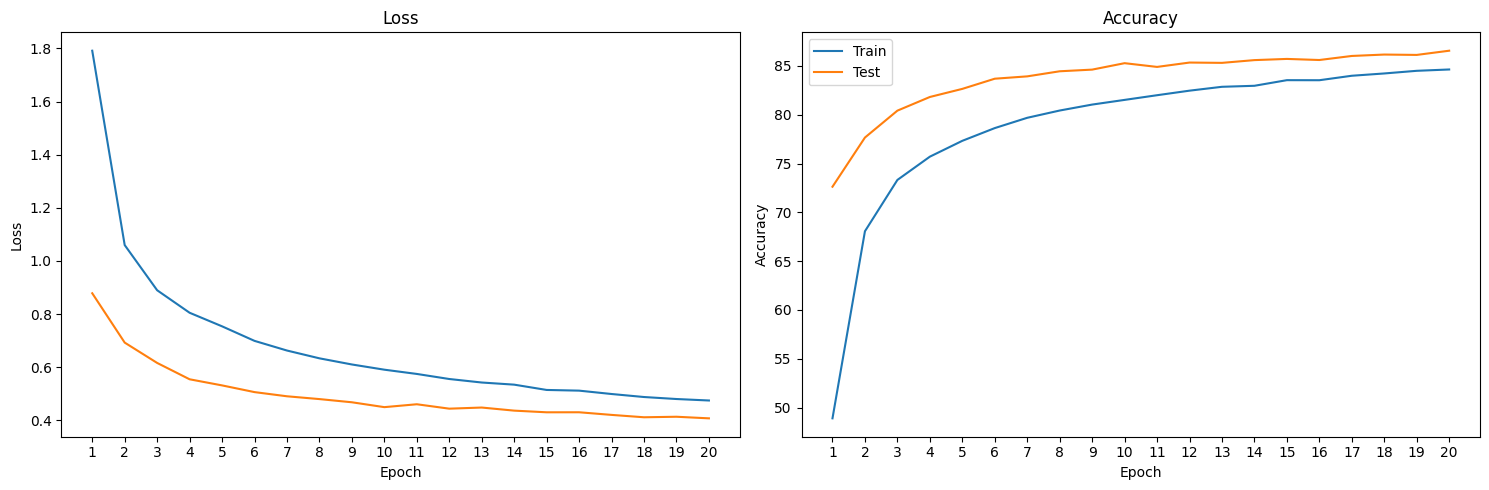

In [14]:
model = BiggerDO(input_size=28*28, num_classes=len(classes)).to(device)

optimizer = optim.Adam(model.parameters(), lr=0.001)

results = train_model(model, 20, optimizer, train_loader, test_loader)

## Step 14 — Continue training with a smaller learning rate
**What changed:** Reuses the current `model` and optimizer setup but sets the Adam learning rate to 0.0001 for 10 additional epochs. A smaller learning rate can make fine-tuning gentler. This cell depends on the preceding cells having run in order; it does not create a new model.

Train Loss = 0.369 | Train Acc = 87.32% | Test Loss = 0.377 | Test Acc = 87.27% : 100%|██████████| 10/10 [06:08<00:00, 36.83s/it]


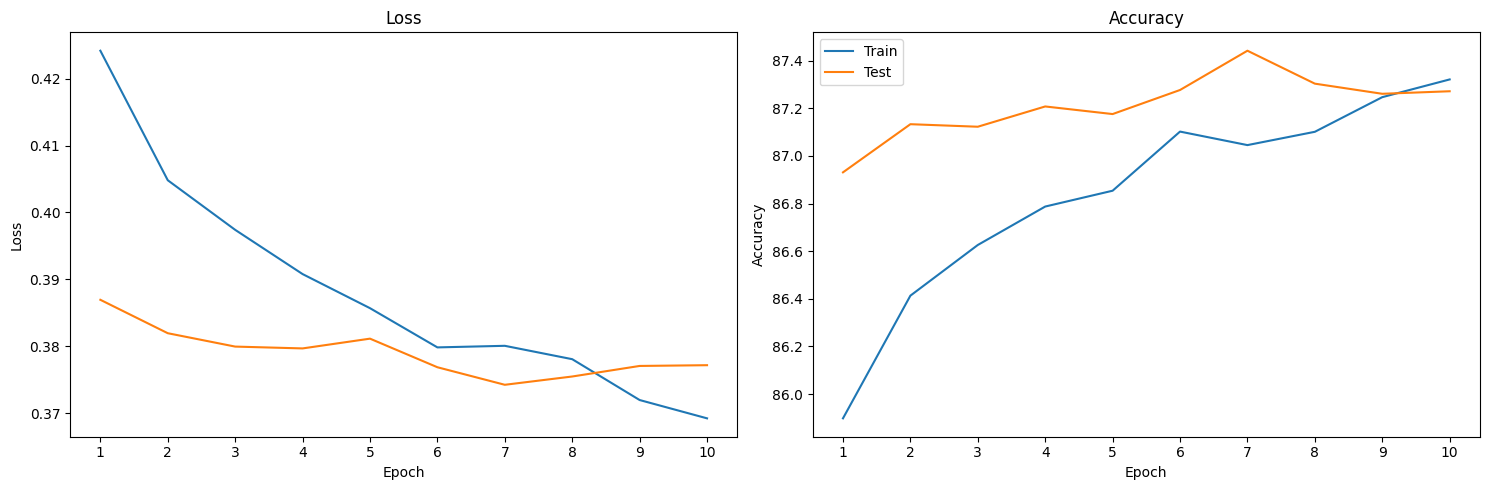

In [15]:
optimizer = optim.Adam(model.parameters(), lr=0.0001)

results = train_model(model, 10, optimizer, train_loader, test_loader)